In [179]:
# ==========================================================
# IMPORT LIBRARIES
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    StandardScaler
)

In [180]:
# ==========================================================
# LOAD DATASET
# ==========================================================

df = pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)

df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [181]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [182]:
# ==========================================================
# BASIC INFORMATION
# ==========================================================

print(df.info())

print("\n")

print(df.describe(include="all"))

print("\n")

print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [183]:
# ==========================================================
# DATASET OVERVIEW
# ==========================================================

print("Rows :", df.shape[0])

print("Columns :", df.shape[1])

print("Duplicate Rows :", df.duplicated().sum())

print("Missing Values :")

display(df.isnull().sum())

Rows : 7043
Columns : 21
Duplicate Rows : 0
Missing Values :


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [184]:
# ==========================================================
# CHECK MISSING VALUES
# ==========================================================

missing = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

display(missing)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [185]:
# ==========================================================
# UNIQUE VALUES
# ==========================================================

for col in df.columns:

    print("="*50)

    print(col)

    print(df[col].nunique())

    print(df[col].unique()[:10])

customerID
7043
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' '7795-CFOCW' '9237-HQITU'
 '9305-CDSKC' '1452-KIOVK' '6713-OKOMC' '7892-POOKP' '6388-TABGU']
gender
2
['Female' 'Male']
SeniorCitizen
2
[0 1]
Partner
2
['Yes' 'No']
Dependents
2
['No' 'Yes']
tenure
73
[ 1 34  2 45  8 22 10 28 62 13]
PhoneService
2
['No' 'Yes']
MultipleLines
3
['No phone service' 'No' 'Yes']
InternetService
3
['DSL' 'Fiber optic' 'No']
OnlineSecurity
3
['No' 'Yes' 'No internet service']
OnlineBackup
3
['Yes' 'No' 'No internet service']
DeviceProtection
3
['No' 'Yes' 'No internet service']
TechSupport
3
['No' 'Yes' 'No internet service']
StreamingTV
3
['No' 'Yes' 'No internet service']
StreamingMovies
3
['No' 'Yes' 'No internet service']
Contract
3
['Month-to-month' 'One year' 'Two year']
PaperlessBilling
2
['Yes' 'No']
PaymentMethod
4
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
MonthlyCharges
1585
[ 29.85  56.95  53.85  42.3   70.7   99.65  89.1   29.75 104.8   56.15]


In [186]:
# ==========================================================
# COLUMN TYPES
# ==========================================================

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numerical Features")

print(numeric_cols)

print()

print("Categorical Features")

print(categorical_cols)

Numerical Features
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical Features
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [187]:
# Check data type
print(df["TotalCharges"].dtype)

# Count blank strings
print((df["TotalCharges"] == " ").sum())

object
11


In [188]:
df.drop(columns=["customerID"], inplace=True)

In [189]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)

In [190]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

In [191]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [192]:
df.dropna(inplace=True)

In [193]:
df.reset_index(drop=True, inplace=True)

In [194]:
print(df.shape)
print(df.isnull().sum().sum())

(7032, 20)
0


In [195]:
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(df[col].value_counts())


gender
gender
Male      3549
Female    3483
Name: count, dtype: int64

Partner
Partner
No     3639
Yes    3393
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2099
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6352
No      680
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3385
Yes                 2967
No phone service     680
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3497
Yes                    2015
No internet service    1520
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3087
Yes                    2425
No internet service    1520
Name: count, dtype: int64

DeviceProtection
DeviceProtection
No                     3094
Yes                    2418
No internet service    1520
Name: count, dtype: int64

TechSupport
TechSupport
No             

In [196]:
# ==========================================================
# FEATURE ENGINEERING
# ==========================================================

# ----------------------------------------------------------
# 1. Total Services
# Count the number of subscribed services
# ----------------------------------------------------------

service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["TotalServices"] = 0

for col in service_columns:
    df["TotalServices"] += df[col].isin(["Yes"]).astype(int)

print("✓ TotalServices created")

✓ TotalServices created


In [197]:
# ----------------------------------------------------------
# 2. Customer Lifetime Value (Proxy)
# ----------------------------------------------------------

df["LifetimeValue"] = (
    df["MonthlyCharges"] *
    df["tenure"]
)

print("✓ LifetimeValue created")

✓ LifetimeValue created


In [198]:
# ----------------------------------------------------------
# 3. Average Monthly Spend
# ----------------------------------------------------------

df["AvgMonthlySpend"] = (
    df["TotalCharges"] /
    df["tenure"]
)

print("✓ AvgMonthlySpend created")

✓ AvgMonthlySpend created


In [199]:
# ----------------------------------------------------------
# 4. Internet User
# ----------------------------------------------------------

df["HasInternet"] = (
    df["InternetService"] != "No"
).astype(int)

print("✓ HasInternet created")

✓ HasInternet created


In [200]:
# ----------------------------------------------------------
# 5. Protection Score
# ----------------------------------------------------------

protection_columns = [
    "OnlineSecurity",
    "DeviceProtection",
    "TechSupport"
]

df["ProtectionScore"] = 0

for col in protection_columns:
    df["ProtectionScore"] += (
        df[col] == "Yes"
    ).astype(int)

print("✓ ProtectionScore created")

✓ ProtectionScore created


In [201]:
# Base services
df["TotalServices"] = (
    (df["PhoneService"] == "Yes").astype(int)
    + (df["MultipleLines"] == "Yes").astype(int)
    + (df["InternetService"] != "No").astype(int)
    + (df["OnlineSecurity"] == "Yes").astype(int)
    + (df["OnlineBackup"] == "Yes").astype(int)
    + (df["DeviceProtection"] == "Yes").astype(int)
    + (df["TechSupport"] == "Yes").astype(int)
    + (df["StreamingTV"] == "Yes").astype(int)
    + (df["StreamingMovies"] == "Yes").astype(int)
)

In [202]:
# ==========================================================
# LABEL ENCODING
# ==========================================================

binary_mapping = {
    "Yes": 1,
    "No": 0,
    "Male": 1,
    "Female": 0
}

binary_columns = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
    "Churn"
]

for col in binary_columns:
    df[col] = df[col].map(binary_mapping)

print("✓ Binary columns encoded")

✓ Binary columns encoded


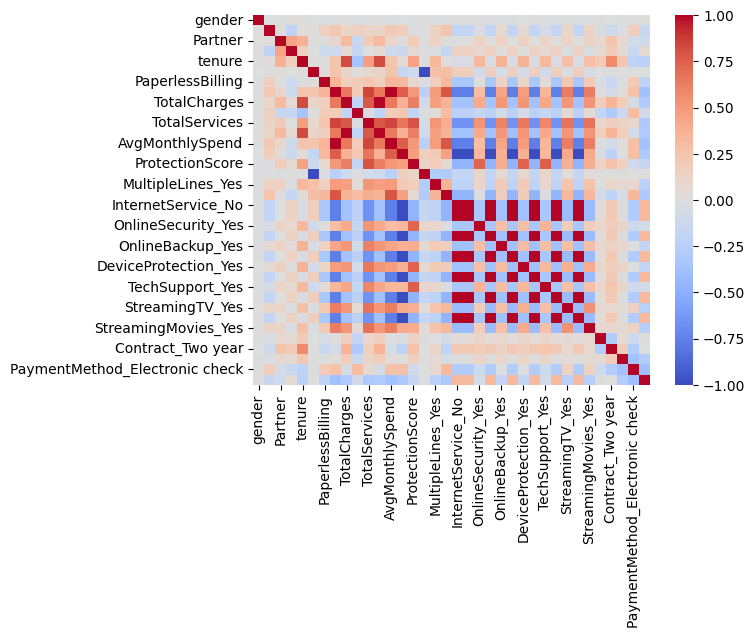

In [211]:
import matplotlib.pyplot as plt
import seaborn as sns


corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap="coolwarm")

# Show the plot
plt.show()

In [203]:
# ==========================================================
# ONE-HOT ENCODING
# ==========================================================

multi_columns = [
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaymentMethod"
]

df = pd.get_dummies(
    df,
    columns=multi_columns,
    drop_first=True,
    dtype=int
)

print("✓ One-Hot Encoding completed")

✓ One-Hot Encoding completed


In [204]:
print(df.shape)

df.head()

(7032, 36)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


In [205]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 36 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7032 non-null   int64  
 1   SeniorCitizen                          7032 non-null   int64  
 2   Partner                                7032 non-null   int64  
 3   Dependents                             7032 non-null   int64  
 4   tenure                                 7032 non-null   int64  
 5   PhoneService                           7032 non-null   int64  
 6   PaperlessBilling                       7032 non-null   int64  
 7   MonthlyCharges                         7032 non-null   float64
 8   TotalCharges                           7032 non-null   float64
 9   Churn                                  7032 non-null   int64  
 10  TotalServices                          7032 non-null   int64  
 11  Life

In [206]:
print(df["Churn"].value_counts())

print(df["Churn"].value_counts(normalize=True) * 100)

Churn
0    5163
1    1869
Name: count, dtype: int64
Churn
0    73.421502
1    26.578498
Name: proportion, dtype: float64


In [208]:
# ==========================================================
# SAVE PREPROCESSED DATASET
# ==========================================================

print(df.head(10))
df.to_csv("telco_preprocessed.csv", index=False)

print("✓ Preprocessed dataset saved successfully!")

   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   
2       1              0        0           0       2             1   
3       1              0        0           0      45             0   
4       0              0        0           0       2             1   
5       0              0        0           0       8             1   
6       1              0        0           1      22             1   
7       0              0        0           0      10             0   
8       0              0        1           0      28             1   
9       1              0        0           1      62             1   

   PaperlessBilling  MonthlyCharges  TotalCharges  Churn  ...  \
0                 1           29.85         29.85      0  ...   
1                 0           56.95       1889.50      0  ...   
2                 1    